## Dataset

Link : https://www.kaggle.com/datasets/yusufdelikkaya/online-sales-dataset

Dataset adalah dataset penjualan online yang berisi berbagai informasi terkait transaksi penjualan produk.

Dataset ini dapat digunakan untuk analisis penjualan, pemahaman perilaku pelanggan, manajemen inventaris, dan perencanaan strategi pemasaran. Informasi dalam dataset ini juga berguna untuk mengidentifikasi tren penjualan berdasarkan kategori produk, lokasi, dan metode pembayaran.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from datetime import datetime
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

##Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/online_sales_dataset.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Discount,PaymentMethod,ShippingCost,Category,SalesChannel,ReturnStatus,ShipmentProvider,WarehouseLocation,OrderPriority
0,221958,SKU_1964,White Mug,38,2020-01-01 00:00,1.71,37039.0,Australia,0.470000,Bank Transfer,10.79,Apparel,In-store,Not Returned,UPS,London,Medium
1,771155,SKU_1241,White Mug,18,2020-01-01 01:00,41.25,19144.0,Spain,0.190000,paypall,9.51,Electronics,Online,Not Returned,UPS,Rome,Medium
2,231932,SKU_1501,Headphones,49,2020-01-01 02:00,29.11,50472.0,Germany,0.350000,Bank Transfer,23.03,Electronics,Online,Returned,UPS,Berlin,High
3,465838,SKU_1760,Desk Lamp,14,2020-01-01 03:00,76.68,96586.0,Netherlands,0.140000,paypall,11.08,Accessories,Online,Not Returned,Royal Mail,Rome,Low
4,359178,SKU_1386,USB Cable,-30,2020-01-01 04:00,-68.11,NaN,United Kingdom,1.501433,Bank Transfer,NaN,Electronics,In-store,Not Returned,FedEx,NaN,Medium


#Data Understanding

In [ ]:
df.shape

(49782, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49782 entries, 0 to 49781
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   InvoiceNo          49782 non-null  int64  
 1   StockCode          49782 non-null  object 
 2   Description        49782 non-null  object 
 3   Quantity           49782 non-null  int64  
 4   InvoiceDate        49782 non-null  object 
 5   UnitPrice          49782 non-null  float64
 6   CustomerID         44804 non-null  float64
 7   Country            49782 non-null  object 
 8   Discount           49782 non-null  float64
 9   PaymentMethod      49782 non-null  object 
 10  ShippingCost       47293 non-null  float64
 11  Category           49782 non-null  object 
 12  SalesChannel       49782 non-null  object 
 13  ReturnStatus       49782 non-null  object 
 14  ShipmentProvider   49782 non-null  object 
 15  WarehouseLocation  46297 non-null  object 
 16  OrderPriority      497

In [ ]:
df.describe()

,InvoiceNo,Quantity,UnitPrice,CustomerID,Discount,ShippingCost
count,49782.000000,49782.000000,49782.000000,44804.000000,49782.000000,47293.000000
mean,550681.239946,22.372343,47.537862,55032.871775,0.275748,17.494529
std,260703.009944,17.917774,33.479510,25913.660157,0.230077,7.220557
min,100005.000000,-50.000000,-99.980000,10001.000000,0.000000,5.000000
25%,324543.000000,11.000000,23.592500,32750.750000,0.130000,11.220000
50%,552244.000000,23.000000,48.920000,55165.000000,0.260000,17.500000
75%,776364.000000,37.000000,74.610000,77306.250000,0.380000,23.720000
max,999997.000000,49.000000,100.000000,99998.000000,1.999764,30.000000


In [ ]:
df['CustomerID'].nunique()

35389

In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,4978
Country,0
Discount,0
PaymentMethod,0


In [ ]:
df.duplicated().sum()

0

## EDA

In [ ]:
#@title Distribusi Jumlah Pembelian (Quatity)

total_qty = df['Quantity'].sum()
print("Total Quantity:", total_qty)

Total Quantity: 1113740


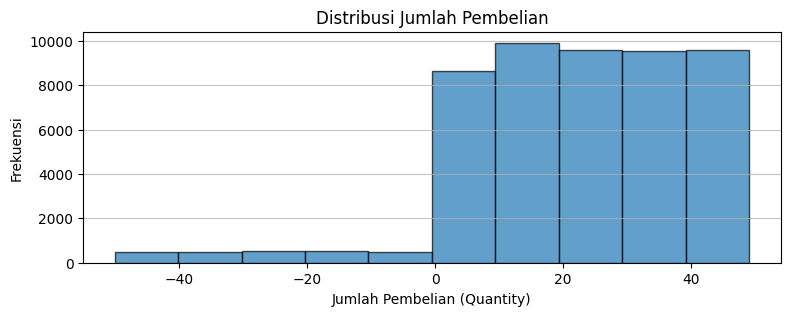

In [ ]:
plt.figure(figsize=(9, 3))
plt.hist(df['Quantity'], bins=10, edgecolor='black', alpha=0.7)
plt.title('Distribusi Jumlah Pembelian')
plt.xlabel('Jumlah Pembelian (Quantity)')
plt.ylabel('Frekuensi')
plt.grid(axis='y', alpha=0.75)
plt.show()

Total Unit Price: 2366529.83


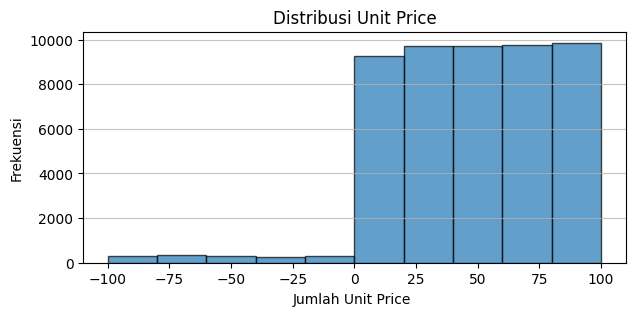

In [ ]:
#@title Distribusi Unit Price

total_unit_price = df['UnitPrice'].sum()
print("Total Unit Price:", total_unit_price)

plt.figure(figsize=(7, 3))
plt.hist(df['UnitPrice'], bins=10, edgecolor='black', alpha=0.7)
plt.title('Distribusi Unit Price')
plt.xlabel('Jumlah Unit Price ')
plt.ylabel('Frekuensi')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
#@title Analisis Jumlah Pelanggan per Negara (Country)

df['Country'].value_counts().head(10)

,count
Country,
France,4230
Sweden,4211
Germany,4182
United Kingdom,4180
Netherlands,4173
Belgium,4170
Portugal,4163
Norway,4157
Australia,4110


In [ ]:
#@title Deteksi Outlier
# Find IQR

IQR = df.Quantity.quantile(0.75) - df.Quantity.quantile(0.25)
Lower_fence = df.Quantity.quantile(0.25) - (IQR * 3)
Upper_fence = df.Quantity.quantile(0.75) + (IQR * 3)
print('Quantity outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

Quantity outliers are values < -67.0 or > 115.0


In [ ]:
#Find IQR for Unit Price
IQR = df.UnitPrice.quantile(0.75) - df.UnitPrice.quantile(0.25)
Lower_fence = df.UnitPrice.quantile(0.25) - (IQR * 3)
Upper_fence = df.UnitPrice.quantile(0.75) + (IQR * 3)
print('UnitPrice outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

UnitPrice outliers are values < -129.46 or > 227.66250000000002


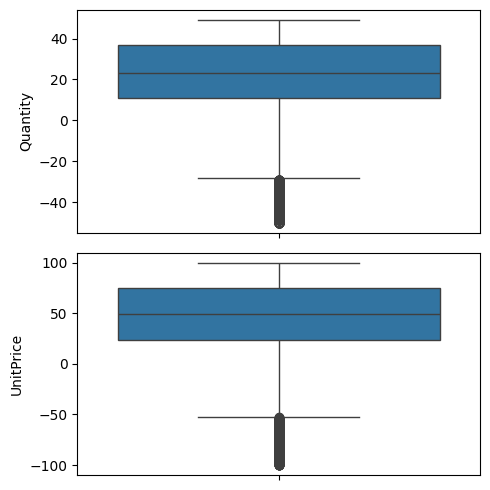

In [ ]:
# Outlier Analysis
fig, axs = plt.subplots(2, figsize = (5,5))
plt1 = sns.boxplot(df['Quantity'], ax = axs[0])
plt2 = sns.boxplot(df['UnitPrice'], ax = axs[1])
plt.tight_layout()

## Data Cleaning

In [ ]:
#@title Menghapus Baris Customer yang kosong
df.dropna(subset=['CustomerID'])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Discount,PaymentMethod,ShippingCost,Category,SalesChannel,ReturnStatus,ShipmentProvider,WarehouseLocation,OrderPriority
0,221958,SKU_1964,White Mug,38,2020-01-01 00:00,1.71,37039.0,Australia,0.47,Bank Transfer,10.79,Apparel,In-store,Not Returned,UPS,London,Medium
1,771155,SKU_1241,White Mug,18,2020-01-01 01:00,41.25,19144.0,Spain,0.19,paypall,9.51,Electronics,Online,Not Returned,UPS,Rome,Medium
2,231932,SKU_1501,Headphones,49,2020-01-01 02:00,29.11,50472.0,Germany,0.35,Bank Transfer,23.03,Electronics,Online,Returned,UPS,Berlin,High
3,465838,SKU_1760,Desk Lamp,14,2020-01-01 03:00,76.68,96586.0,Netherlands,0.14,paypall,11.08,Accessories,Online,Not Returned,Royal Mail,Rome,Low
5,744167,SKU_1006,Office Chair,47,2020-01-01 05:00,70.16,53887.0,Sweden,0.48,Credit Card,13.98,Electronics,Online,Not Returned,DHL,London,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49777,354083,SKU_1562,Blue Pen,25,2025-09-05 01:00,70.92,51445.0,Spain,0.20,Credit Card,8.96,Electronics,Online,Returned,UPS,Berlin,Medium
49778,296698,SKU_1930,USB Cable,7,2025-09-05 02:00,51.74,28879.0,United States,0.23,Bank Transfer,23.55,Electronics,Online,Not Returned,FedEx,Amsterdam,Low
49779,177622,SKU_1766,Office Chair,43,2025-09-05 03:00,85.25,21825.0,Portugal,0.20,Bank Transfer,16.26,Furniture,In-store,Not Returned,FedEx,London,High
49780,701213,SKU_1602,Notebook,48,2025-09-05 04:00,39.64,43199.0,United Kingdom,0.31,paypall,28.56,Apparel,Online,Not Returned,Royal Mail,London,Medium


In [ ]:
#@title Handling Outlier dengan IQR
df_num = ['Quantity', 'UnitPrice']

for col in df_num:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    print(f"Outliers removed from {col} column.")

Outliers removed from Quantity column.
Outliers removed from UnitPrice column.


## Feature Engineering

In [ ]:
#@title Recency
# Jumlah hari sejak transaksi terakhir pelanggan.
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
today = datetime.now()
recency = df.groupby('CustomerID')['InvoiceDate'].max().apply(lambda x: (today - x).days)

In [ ]:
#@title Frequency (Frekuensi Transaksi)
# Jumlah transaksi per pelanggan
frequency = df.groupby('CustomerID')['InvoiceNo'].nunique()

In [ ]:
#@title Monetary (Total Nilai Transaksi)
# Total nilai pembelian per pelanggan

df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
monetary = df.groupby('CustomerID')['TotalPrice'].sum()

In [ ]:
#@title Menggabungkan Fitur Recency, Frequency, dan Monetary (RFM)

rfm = pd.DataFrame({'Recency': recency, 'Frequency': frequency, 'Monetary': monetary})

variabel rfm akan berisi data yang terstruktur dengan tiga metrik penting untuk setiap pelanggan, yang dapat digunakan untuk analisis lebih lanjut, seperti:

Segmentasi Pelanggan: Menggunakan model RFM untuk mengidentifikasi pelanggan yang paling berharga, serta pelanggan yang mungkin perlu ditargetkan dengan kampanye pemasaran.


Analisis Perilaku: Memahami tren pembelian dan perilaku pelanggan berdasarkan waktu terakhir mereka bertransaksi, frekuensi pembelian, dan total pengeluaran mereka.

In [ ]:
#@title Scaling Data

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

Variabel rfm_scaled akan berisi data RFM yang telah dinormalisasi, yang siap digunakan untuk analisis lebih lanjut.

## Modelling

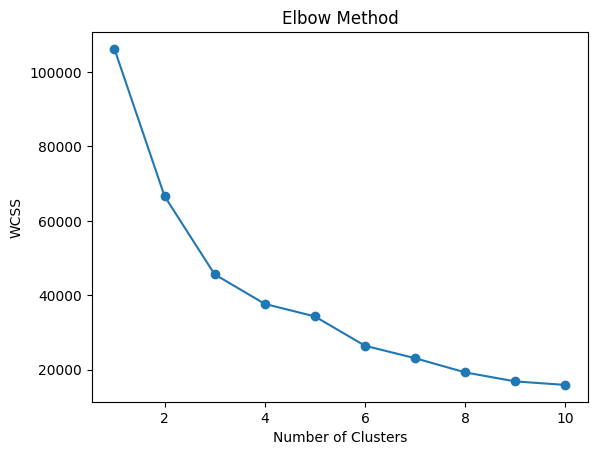

In [ ]:
#@title Menentukan Jumlah Cluster (K)
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

Penjelasan Grafik Elbow Method

Sumbu X (Number of Clusters):
Menunjukkan jumlah cluster (k) yang diuji, dari 1 hingga 10.

Sumbu Y (WCSS):
Menunjukkan nilai Within-Cluster Sum of Squares (WCSS), yang mencerminkan seberapa baik data dikelompokkan. Semakin rendah nilai WCSS, semakin baik pemisahan antara cluster.

Trend Umum:
Grafik menunjukkan bahwa WCSS berkurang secara signifikan saat jumlah cluster meningkat dari 1 ke 2, dan penurunan ini terus terjadi, tetapi dengan laju yang lebih lambat seiring bertambahnya jumlah cluster.


#Contoh algoritma clustering dengan python

In [ ]:
#@title Clustering dengan K-Means
# Membagi data ke dalam 3 cluster
kmeans = KMeans(n_clusters=3, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

## Evaluasi Model

In [ ]:
#@title Silhouette Score
score = silhouette_score(rfm_scaled, rfm['Cluster'])
print(f"Silhouette Score: {score}")

Silhouette Score: 0.3833888865997298


Skor 0.383 menunjukkan bahwa clustering yang dihasilkan memiliki kualitas yang cukup baik, tetapi masih bisa diperbaiki. Nilai ini menunjukkan bahwa beberapa objek berada cukup dekat dengan cluster mereka tetapi masih ada ruang untuk perbaikan.

In [ ]:
rfm['Cluster'] = kmeans.labels_

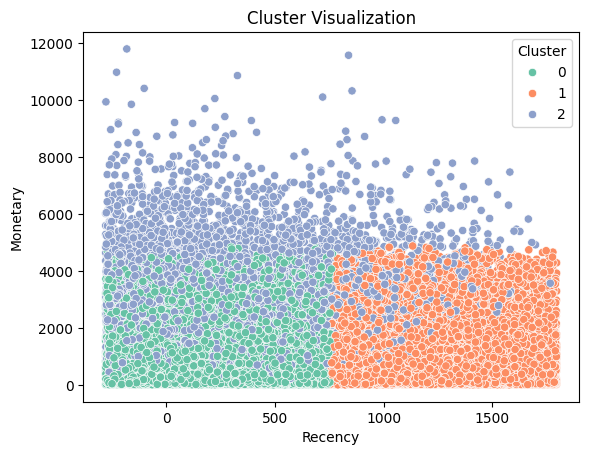

In [ ]:
#@title Visualisasi Cluster
sns.scatterplot(x=rfm['Recency'], y=rfm['Monetary'], hue=rfm['Cluster'], palette='Set2')
plt.title('Cluster Visualization')
plt.show()

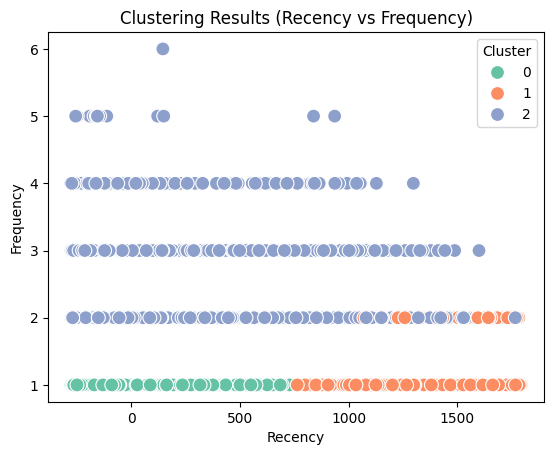

In [ ]:
# Scatter plot: Recency vs Frequency
sns.scatterplot(
    x=rfm['Recency'], y=rfm['Frequency'],
    hue=rfm['Cluster'], palette='Set2', s=100
)
plt.title("Clustering Results (Recency vs Frequency)")
plt.xlabel("Recency")
plt.ylabel("Frequency")
plt.legend(title="Cluster")
plt.show()

In [ ]:
#@title Interpretasi Cluster
print(rfm.groupby('Cluster').mean().astype(int))

         Recency  Frequency  Monetary
Cluster                              
0            242          1      1260
1           1279          1      1245
2            348          2      2830


Struktur Cluster:
Data dibagi menjadi 3 cluster, masing-masing dengan karakteristik yang berbeda berdasarkan nilai rata-rata dari Recency, Frequency, dan Monetary.

1. Cluster 0:
Recency: 240
Frequency: 1
Monetary: 1260

Interpretasi: Pelanggan di cluster ini relatif baru (240 hari sejak pembelian terakhir) tetapi memiliki pengeluaran yang tinggi, meskipun frekuensi pembeliannya rendah. Ini mungkin menunjukkan pelanggan yang melakukan pembelian besar tetapi tidak sering bertransaksi.

2. Cluster 1:
Recency: 1277
Frequency: 1
Monetary: 1245

Interpretasi: Pelanggan ini memiliki waktu yang sangat lama sejak pembelian terakhir (1277 hari) dan juga frekuensi transaksi yang rendah. Ini menunjukkan bahwa mereka mungkin adalah pelanggan yang telah berhenti membeli atau tidak aktif, meskipun memiliki pengeluaran yang cukup tinggi saat terakhir kali bertransaksi.

3. Cluster 2:
Recency: 347
Frequency: 2
Monetary: 2831

Interpretasi: Pelanggan di cluster ini memiliki frekuensi transaksi yang lebih tinggi (2 kali) dan juga pengeluaran yang lebih besar (2831). Mereka juga relatif baru dibandingkan dengan cluster 1, menunjukkan bahwa mereka mungkin adalah pelanggan yang lebih aktif dan loyal.

In [ ]:
#@title Menggunakan Model K-Means dengan Data Baru
# Load model dan scaler

import joblib
# Simpan model dan scaler
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [ ]:
print(new_data.columns)

Index(['Recency', 'Frequency', 'Monetary'], dtype='object')


In [ ]:
# Since the previously saved model isn't compatible,
# we'll retrain it using the original rfm_scaled data:
kmeans = KMeans(n_clusters=3, random_state=42)  # Using the same parameters as before
kmeans.fit(rfm_scaled)

scaler = StandardScaler()
# Fit the scaler to original RFM data, EXCLUDING the 'Cluster' column
scaler.fit(rfm[['Recency', 'Frequency', 'Monetary']])

# Contoh data baru (pastikan jumlah fitur di sini konsisten)
new_data = pd.DataFrame({
    'Recency': [300, 1300],    # Ganti dengan nilai sesuai
    'Frequency': [2, 1],
    'Monetary': [1500, 1200]
})

# Pastikan untuk menggunakan fitur yang sama
if new_data.shape[1] != 3:  # Sesuaikan dengan jumlah fitur yang digunakan saat pelatihan
    raise ValueError("Jumlah fitur pada data baru tidak sesuai dengan model.")

# Normalisasi data baru
scaled_new_data = scaler.transform(new_data)

# Prediksi cluster untuk data baru
predictions = kmeans.predict(scaled_new_data)

# Tampilkan hasil
print("Prediksi cluster untuk data baru:", predictions)

Prediksi cluster untuk data baru: [2 1]


1. Prediksi Cluster:

Angka dalam array [2 1] menunjukkan cluster yang diprediksi untuk masing-masing entri dalam new_data.

Cluster 2: Entitas pertama dalam new_data (dengan Recency 300, Frequency 2, dan Monetary 1500) dikategorikan ke dalam Cluster 2.

Cluster 1: Entitas kedua dalam new_data (dengan Recency 1300, Frequency 1, dan Monetary 1200) masuk ke dalam Cluster 1.

2. Interpretasi:
Angka cluster menunjukkan bagaimana model K-Means mengelompokkan data baru berdasarkan karakteristiknya. Setiap cluster mewakili grup data dengan kesamaan tertentu.

Dalam konteks analisis RFM (Recency, Frequency, Monetary), cluster dapat merepresentasikan segmen pelanggan yang berbeda yang memiliki perilaku serupa. Misalnya, pelanggan dalam Cluster 2 mungkin lebih aktif dalam berbelanja dibandingkan yang ada di Cluster 1.

In [ ]:
# Menggunakan Model K-Means dengan Data Baru
# Load model dan scaler
kmeans = joblib.load('kmeans_model.pkl')
scaler = joblib.load('scaler.pkl')

# Contoh data baru (pastikan jumlah fitur di sini konsisten)
new_data = pd.DataFrame({
    'Recency': [300, 1300],    # Ganti dengan nilai sesuai
    'Frequency': [2, 1],
    'Monetary': [1500, 1200]
})

# Pastikan untuk menggunakan fitur yang sama
if new_data.shape[1] != 3:  # Sesuaikan dengan jumlah fitur yang digunakan saat pelatihan
    raise ValueError("Jumlah fitur pada data baru tidak sesuai dengan model.")

# Normalisasi data baru
scaled_new_data = scaler.transform(new_data)

# Prediksi cluster untuk data baru
predictions = kmeans.predict(scaled_new_data)

# Tampilkan hasil
print("Prediksi cluster untuk data baru:", predictions)

ValueError: X has 3 features, but KMeans is expecting 2 features as input.

In [ ]:
import pickle
import numpy as np
from sklearn.cluster import KMeans

# Contoh data untuk pelatihan
data = np.array([[1, 2], [1, 4], [1, 0],
                 [4, 2], [4, 4], [4, 0]])

# Melatih model K-means
kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(data)

# Menyimpan model ke file
with open('model_kmeans.pkl', 'wb') as file:
    pickle.dump(kmeans, file)

In [ ]:
import pickle
import numpy as np

# Data baru untuk pengujian
new_data = np.array([[0, 0], [4, 4], [5, 5]])

# Memuat model yang telah disimpan
with open('model_kmeans.pkl', 'rb') as file:
    kmeans = pickle.load(file)

# Melakukan prediksi kluster untuk data baru
predictions = kmeans.predict(new_data)

# Menampilkan hasil prediksi
print("Prediksi kluster untuk data baru:", predictions)

Prediksi kluster untuk data baru: [1 0 0]


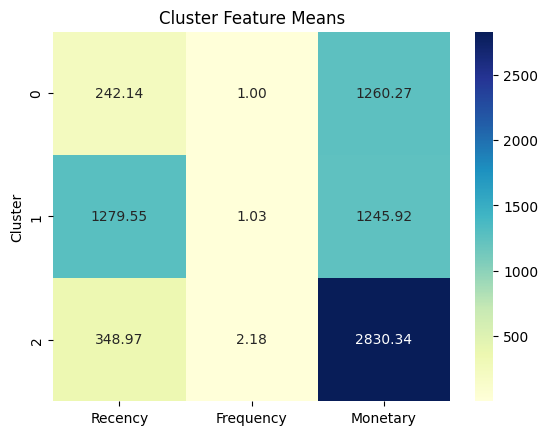

In [ ]:
cluster_means = rfm.groupby('Cluster').mean()

# Heatmap
sns.heatmap(cluster_means, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title("Cluster Feature Means")
plt.show()